Saving input.jpg to input (4).jpg
Image dimensions: 200 x 300


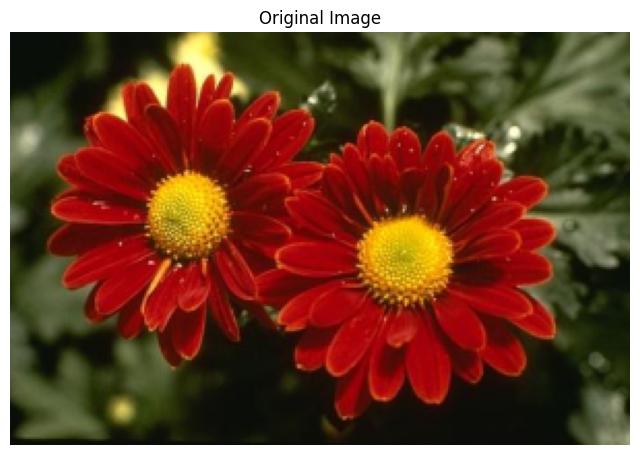

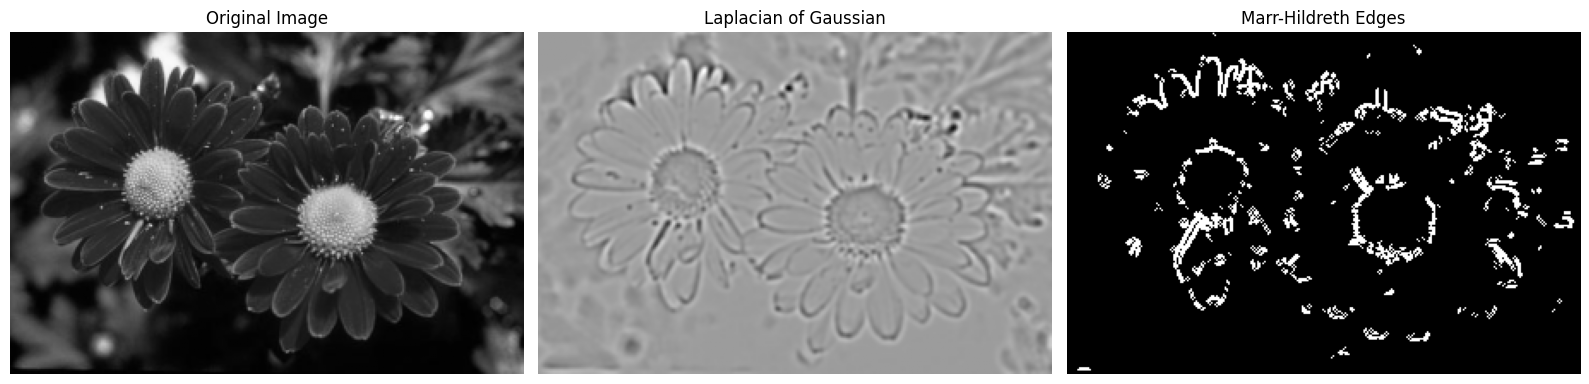

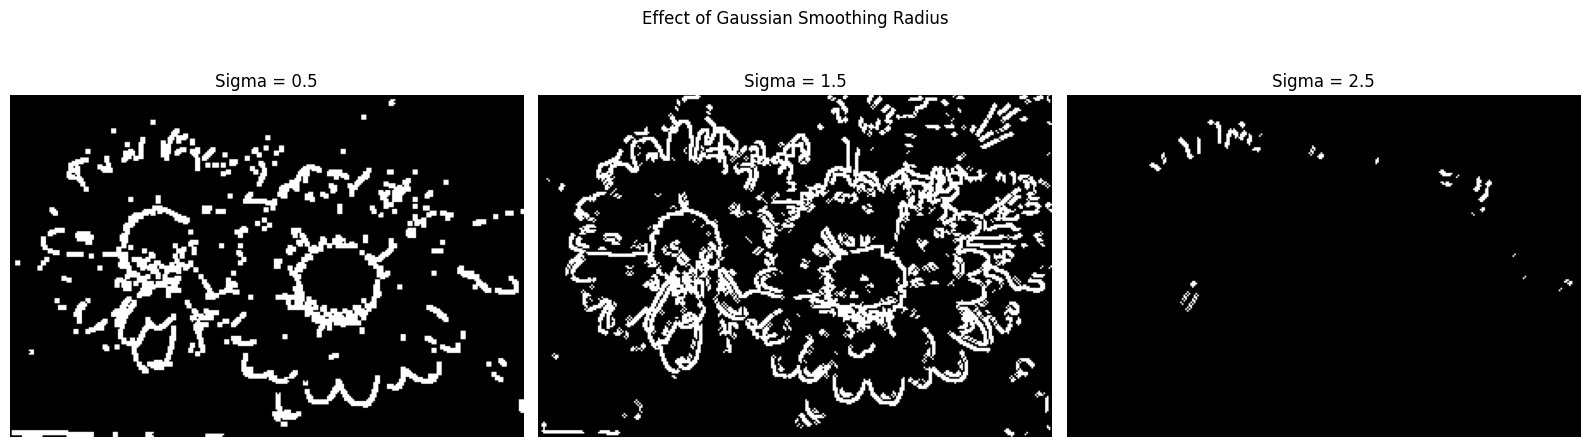

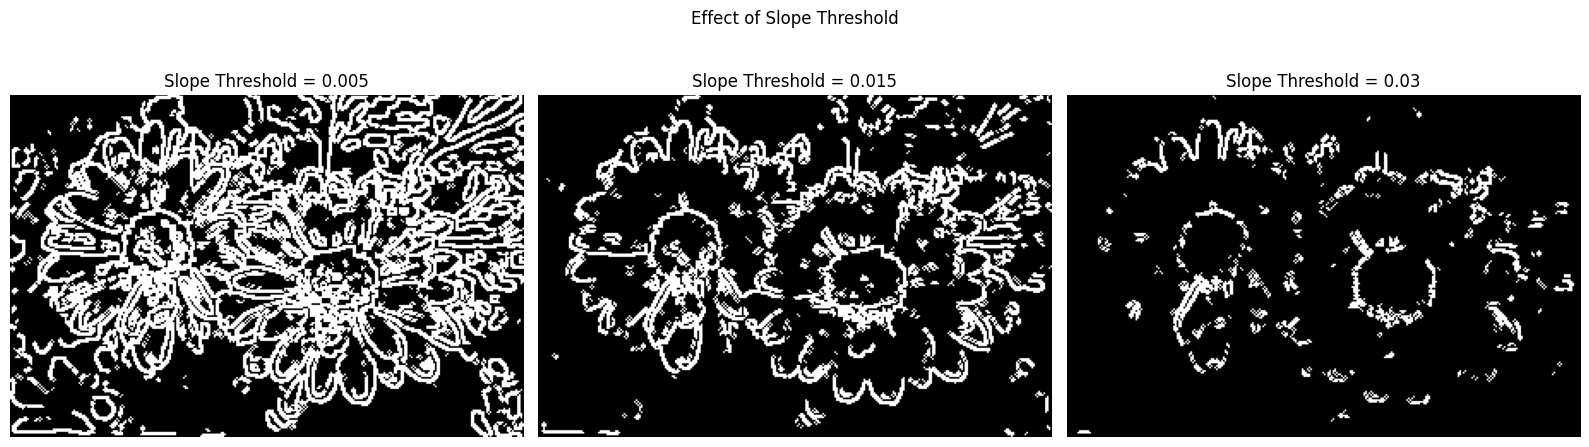

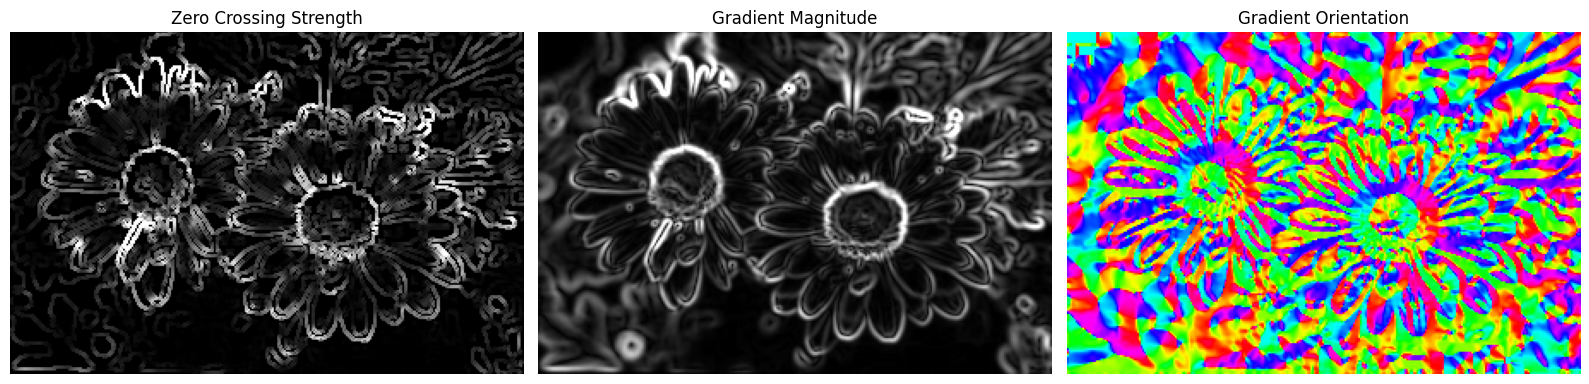

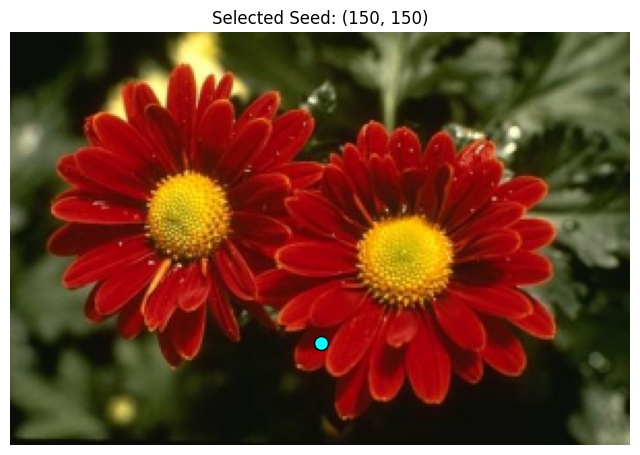

Running Dijkstra: Zero Crossing Only
Running Dijkstra: Gradient Magnitude Only
Running Dijkstra: Gradient Orientation Only
Running Dijkstra: Combined Weight


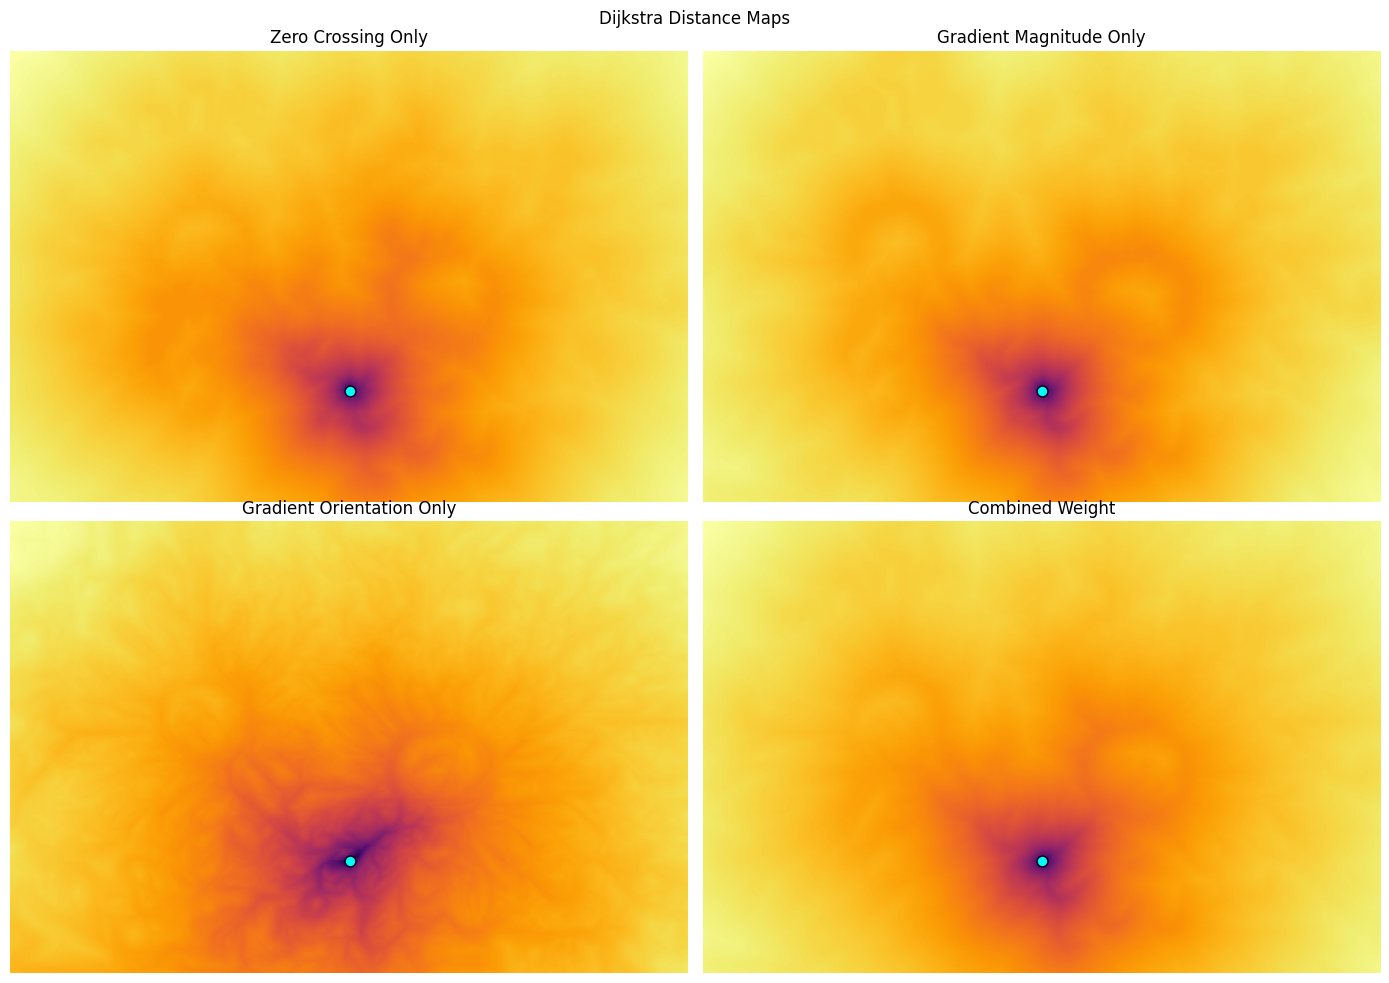

Number of boundary seeds: 16


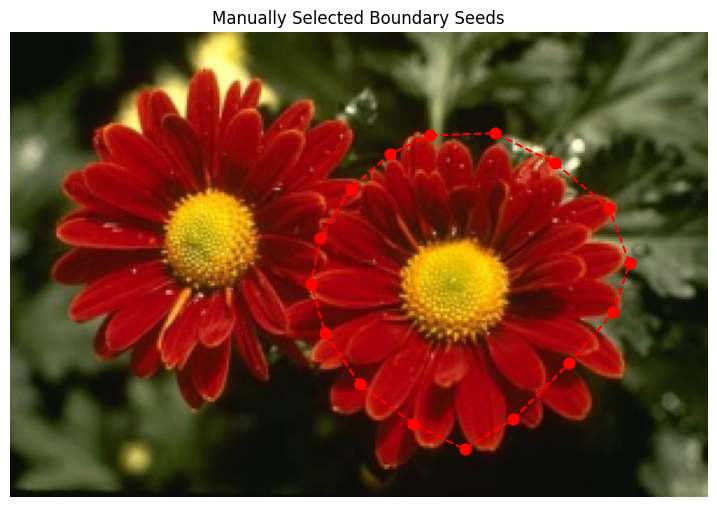

Connecting seed 1 to seed 2
Connecting seed 2 to seed 3
Connecting seed 3 to seed 4
Connecting seed 4 to seed 5
Connecting seed 5 to seed 6
Connecting seed 6 to seed 7
Connecting seed 7 to seed 8
Connecting seed 8 to seed 9
Connecting seed 9 to seed 10
Connecting seed 10 to seed 11
Connecting seed 11 to seed 12
Connecting seed 12 to seed 13
Connecting seed 13 to seed 14
Connecting seed 14 to seed 15
Connecting seed 15 to seed 16
Connecting seed 16 to seed 1


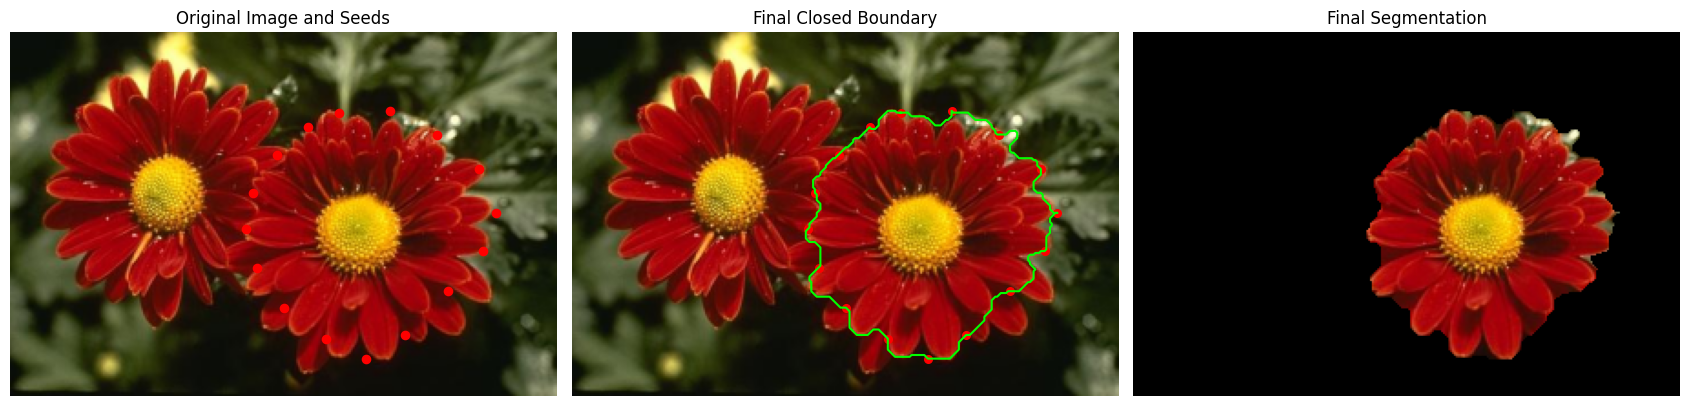

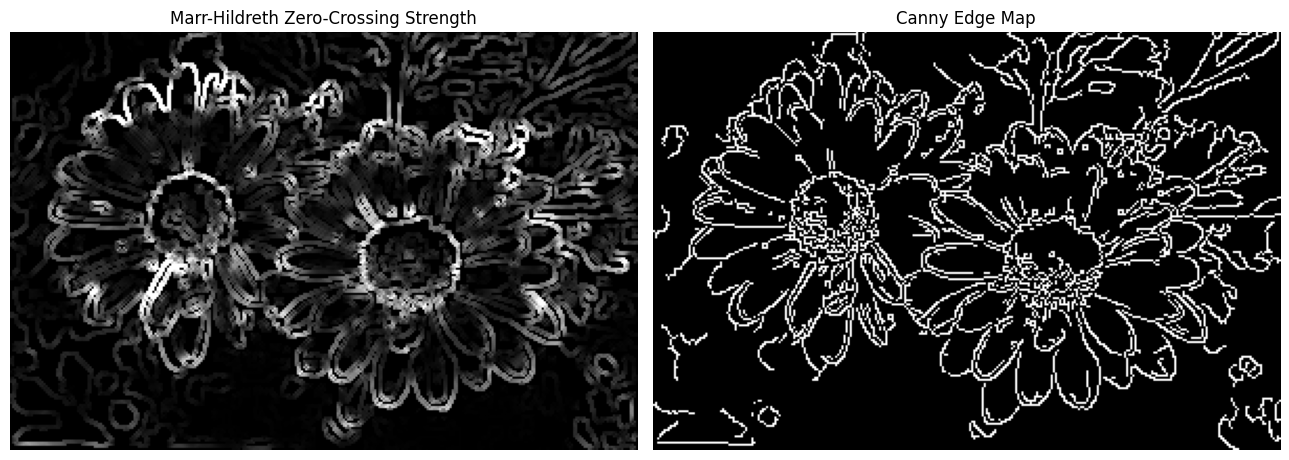

Connecting seed 1 to seed 2
Connecting seed 2 to seed 3
Connecting seed 3 to seed 4
Connecting seed 4 to seed 5
Connecting seed 5 to seed 6
Connecting seed 6 to seed 7
Connecting seed 7 to seed 8
Connecting seed 8 to seed 9
Connecting seed 9 to seed 10
Connecting seed 10 to seed 11
Connecting seed 11 to seed 12
Connecting seed 12 to seed 13
Connecting seed 13 to seed 14
Connecting seed 14 to seed 15
Connecting seed 15 to seed 16
Connecting seed 16 to seed 1


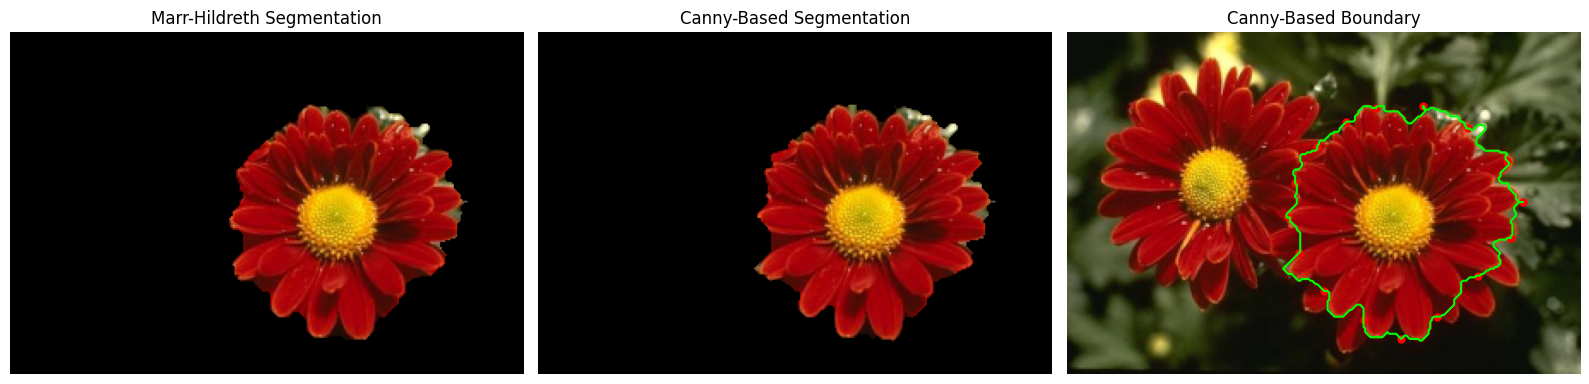

Connecting seed 1 to seed 2
Connecting seed 2 to seed 3
Connecting seed 3 to seed 4
Connecting seed 4 to seed 5
Connecting seed 5 to seed 6
Connecting seed 6 to seed 7
Connecting seed 7 to seed 8
Connecting seed 8 to seed 9
Connecting seed 9 to seed 10
Connecting seed 10 to seed 11
Connecting seed 11 to seed 12
Connecting seed 12 to seed 13
Connecting seed 13 to seed 14
Connecting seed 14 to seed 15
Connecting seed 15 to seed 16
Connecting seed 16 to seed 1


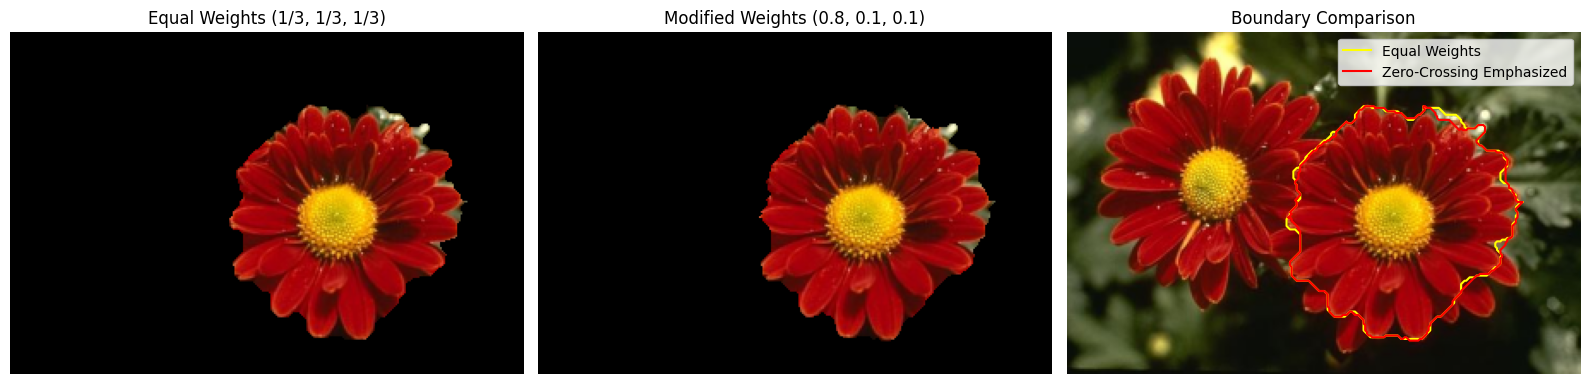

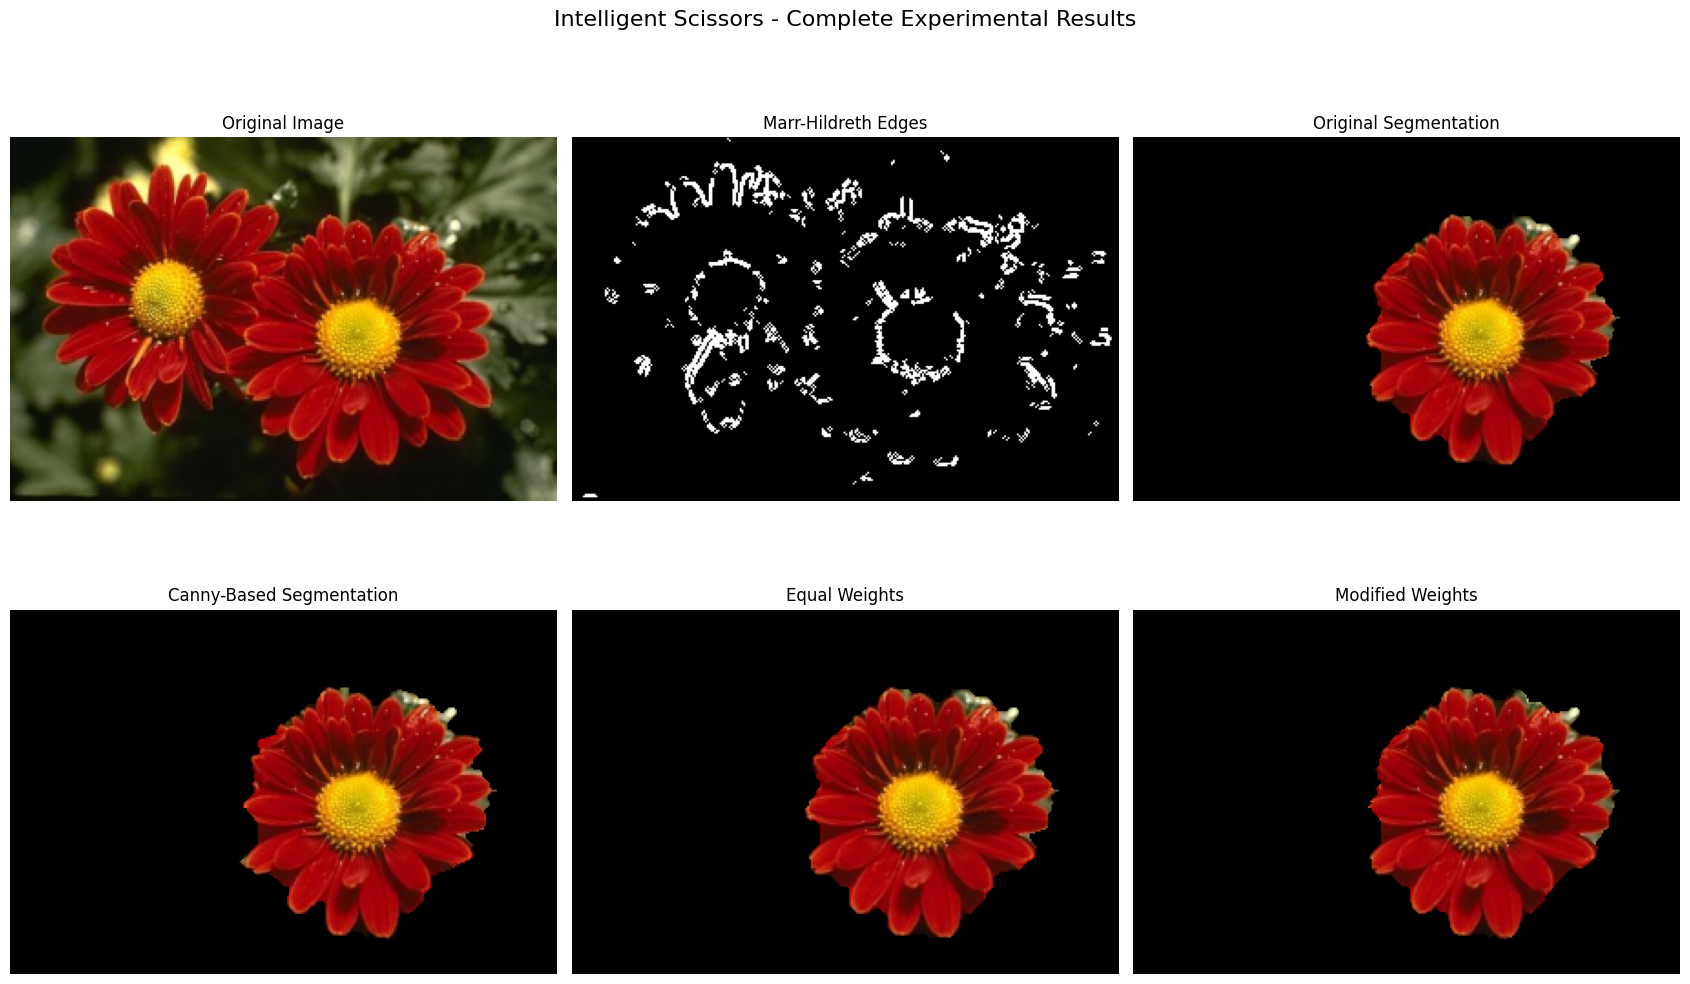

True

In [61]:

# ================================================================
# INTELLIGENT SCISSORS - COMPLETE ASSIGNMENT IMPLEMENTATION
# Marr-Hildreth + Dijkstra + Interactive Segmentation
# ================================================================

!pip -q install numpy scipy matplotlib opencv-python-headless

import cv2
import numpy as np
import matplotlib.pyplot as plt

from scipy.ndimage import gaussian_laplace, gaussian_filter, sobel
from heapq import heappush, heappop
from google.colab import files


# ================================================================
# PART 0: LOAD IMAGE
# ================================================================

uploaded = files.upload()

image_path = next(iter(uploaded))

image_bgr = cv2.imread(image_path)
image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)

gray = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)
gray = gray.astype(np.float32) / 255.0

# Resize image for manageable Dijkstra computation
MAX_SIZE = 300

h, w = gray.shape
scale = min(1.0, MAX_SIZE / max(h, w))

if scale < 1.0:
    new_w = int(w * scale)
    new_h = int(h * scale)

    gray = cv2.resize(gray, (new_w, new_h),
                      interpolation=cv2.INTER_AREA)

    image_rgb = cv2.resize(image_rgb, (new_w, new_h),
                           interpolation=cv2.INTER_AREA)

H, W = gray.shape

print("Image dimensions:", H, "x", W)

plt.figure(figsize=(8, 6))
plt.imshow(image_rgb)
plt.title("Original Image")
plt.axis("off")
plt.show()


# ================================================================
# PART 1: MARR-HILDRETH EDGE DETECTOR
# ================================================================

def marr_hildreth(image, sigma=1.5, slope_threshold=0.03):

    log_response = gaussian_laplace(image, sigma=sigma)

    H, W = image.shape

    zero_crossings = np.zeros((H, W), dtype=np.uint8)

    # Check all 8-connected neighbours without wraparound
    for dy in [-1, 0, 1]:
        for dx in [-1, 0, 1]:

            if dx == 0 and dy == 0:
                continue

            y1 = max(0, -dy)
            y2 = min(H, H-dy)

            x1 = max(0, -dx)
            x2 = min(W, W-dx)

            current = log_response[y1:y2, x1:x2]

            neighbour = log_response[
                y1+dy:y2+dy,
                x1+dx:x2+dx
            ]

            crossing = (
                (current * neighbour < 0) &
                (np.abs(current - neighbour) >= slope_threshold)
            )

            zero_crossings[y1:y2, x1:x2] |= crossing.astype(np.uint8)

    return log_response, zero_crossings


# Initial parameters
sigma = 1.5
slope_threshold = 0.03

log_response, edges = marr_hildreth(
    gray, sigma, slope_threshold
)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(gray, cmap="gray")
axes[0].set_title("Original Image")

axes[1].imshow(log_response, cmap="gray")
axes[1].set_title("Laplacian of Gaussian")

axes[2].imshow(edges, cmap="gray")
axes[2].set_title("Marr-Hildreth Edges")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


# ================================================================
# PART 1A: EFFECT OF GAUSSIAN SMOOTHING RADIUS
# ================================================================

sigmas = [0.5, 1.5, 2.5]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, s in zip(axes, sigmas):

    _, result = marr_hildreth(
        gray,
        sigma=s,
        slope_threshold=0.015
    )

    ax.imshow(result, cmap="gray")
    ax.set_title(f"Sigma = {s}")
    ax.axis("off")

plt.suptitle("Effect of Gaussian Smoothing Radius")
plt.tight_layout()
plt.show()


# ================================================================
# PART 1B: EFFECT OF SLOPE THRESHOLD
# ================================================================

thresholds = [0.005, 0.015, 0.03]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, t in zip(axes, thresholds):

    _, result = marr_hildreth(
        gray,
        sigma=1.5,
        slope_threshold=t
    )

    ax.imshow(result, cmap="gray")
    ax.set_title(f"Slope Threshold = {t}")
    ax.axis("off")

plt.suptitle("Effect of Slope Threshold")
plt.tight_layout()
plt.show()


# ================================================================
# PART 2: COMPUTE IMAGE FEATURES
# ================================================================

def compute_features(image, sigma=1.5, slope_threshold=0.03):

    log_response, zero_crossings = marr_hildreth(
        image, sigma, slope_threshold
    )

    # Smooth before computing gradients
    smoothed = gaussian_filter(image, sigma=1.0)

    gx = sobel(smoothed, axis=1)
    gy = sobel(smoothed, axis=0)

    magnitude = np.sqrt(gx**2 + gy**2)

    orientation = np.arctan2(gy, gx)

    # Calculate zero-crossing strength
    H, W = image.shape
    zero_strength = np.zeros_like(image)

    for dy in [-1, 0, 1]:
        for dx in [-1, 0, 1]:

            if dx == 0 and dy == 0:
                continue

            y1 = max(0, -dy)
            y2 = min(H, H-dy)

            x1 = max(0, -dx)
            x2 = min(W, W-dx)

            current = log_response[y1:y2, x1:x2]

            neighbour = log_response[
                y1+dy:y2+dy,
                x1+dx:x2+dx
            ]

            crossing = current * neighbour < 0

            strength = np.abs(current - neighbour)

            zero_strength[y1:y2, x1:x2] = np.maximum(
                zero_strength[y1:y2, x1:x2],
                strength * crossing
            )

    # Robust normalization
    def normalize(x):

        scale = np.percentile(x, 99)

        if scale < 1e-12:
            return np.zeros_like(x)

        return np.clip(x / scale, 0, 1)

    zero_strength = normalize(zero_strength)
    magnitude = normalize(magnitude)

    return {
        "log": log_response,
        "zero_crossings": zero_crossings,
        "zero_strength": zero_strength,
        "magnitude": magnitude,
        "orientation": orientation,
        "gx": gx,
        "gy": gy
    }


features = compute_features(gray)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(features["zero_strength"], cmap="gray")
axes[0].set_title("Zero Crossing Strength")

axes[1].imshow(features["magnitude"], cmap="gray")
axes[1].set_title("Gradient Magnitude")

axes[2].imshow(features["orientation"], cmap="hsv")
axes[2].set_title("Gradient Orientation")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


# ================================================================
# PART 2A: DEFINE 8-CONNECTED NEIGHBOURS
# ================================================================

NEIGHBOURS = [
    (-1, -1), (-1, 0), (-1, 1),
    (0, -1),           (0, 1),
    (1, -1),  (1, 0),  (1, 1)
]


# ================================================================
# PART 2B: SYMMETRIC EDGE WEIGHT FUNCTION
# ================================================================

def get_edge_cost(y, x, ny, nx, features,
                  mode="combined",
                  weights=(1/3, 1/3, 1/3)):

    # Average zero-crossing cost at both endpoints
    cz = 1.0 - 0.5 * (
        features["zero_strength"][y, x] +
        features["zero_strength"][ny, nx]
    )

    # Average gradient magnitude cost
    cg = 1.0 - 0.5 * (
        features["magnitude"][y, x] +
        features["magnitude"][ny, nx]
    )

    # Unit movement direction
    dx = nx - x
    dy = ny - y

    length = np.sqrt(dx**2 + dy**2)

    dx /= length
    dy /= length

    # Orientation cost at both endpoints
    orientation_costs = []

    for py, px in [(y, x), (ny, nx)]:

        gx = features["gx"][py, px]
        gy = features["gy"][py, px]

        norm = np.sqrt(gx**2 + gy**2)

        if norm < 1e-10:
            co = 0.5
        else:
            co = abs((gx/norm)*dx + (gy/norm)*dy)

        orientation_costs.append(co)

    co = np.mean(orientation_costs)

    if mode == "zero":
        cost = cz

    elif mode == "magnitude":
        cost = cg

    elif mode == "orientation":
        cost = co

    elif mode == "combined":
        wz, wg, wo = weights
        cost = wz*cz + wg*cg + wo*co

    else:
        raise ValueError("Invalid mode")

    # Include diagonal movement distance
    return length * (cost + 1e-4)


# ================================================================
# PART 2C: DIJKSTRA'S ALGORITHM
# ================================================================

def dijkstra(features, seed, mode="combined",
             weights=(1/3, 1/3, 1/3),
             target=None):

    H, W = features["magnitude"].shape

    sy, sx = seed

    distances = np.full((H, W), np.inf)

    predecessors = np.full(
        (H, W, 2), -1, dtype=np.int32
    )

    visited = np.zeros((H, W), dtype=bool)

    distances[sy, sx] = 0

    pq = [(0.0, sy, sx)]

    while pq:

        current_dist, y, x = heappop(pq)

        if visited[y, x]:
            continue

        visited[y, x] = True

        # Early stopping when target is reached
        if target is not None and (y, x) == target:
            break

        for dy, dx in NEIGHBOURS:

            ny = y + dy
            nx = x + dx

            if not (0 <= ny < H and 0 <= nx < W):
                continue

            if visited[ny, nx]:
                continue

            edge_weight = get_edge_cost(
                y, x, ny, nx,
                features,
                mode=mode,
                weights=weights
            )

            new_dist = current_dist + edge_weight

            if new_dist < distances[ny, nx]:

                distances[ny, nx] = new_dist

                predecessors[ny, nx] = [y, x]

                heappush(pq, (new_dist, ny, nx))

    return distances, predecessors


# ================================================================
# PART 2D: SELECT A MANUAL SEED
# ================================================================

seed = (150, 150)  # (row, column)

assert 0 <= seed[0] < H and 0 <= seed[1] < W

plt.figure(figsize=(8, 6))
plt.imshow(image_rgb)

plt.scatter(
    seed[1], seed[0],
    color="cyan", s=100,
    edgecolors="black"
)

plt.title(f"Selected Seed: {seed}")
plt.axis("off")
plt.show()


# ================================================================
# PART 2E: RUN DIJKSTRA WITH FOUR WEIGHT FUNCTIONS
# ================================================================

modes = [
    ("zero", "Zero Crossing Only"),
    ("magnitude", "Gradient Magnitude Only"),
    ("orientation", "Gradient Orientation Only"),
    ("combined", "Combined Weight")
]

distance_maps = {}
predecessor_maps = {}

for mode, title in modes:

    print("Running Dijkstra:", title)

    distances, predecessors = dijkstra(
        features,
        seed,
        mode=mode
    )

    distance_maps[mode] = distances
    predecessor_maps[mode] = predecessors


fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, (mode, title) in zip(axes.ravel(), modes):

    ax.imshow(
        np.log1p(distance_maps[mode]),
        cmap="inferno"
    )

    ax.scatter(
        seed[1], seed[0],
        c="cyan", s=60,
        edgecolors="black"
    )

    ax.set_title(title)
    ax.axis("off")

plt.suptitle("Dijkstra Distance Maps")
plt.tight_layout()
plt.show()


# ================================================================
# PART 3: INTELLIGENT SCISSORS SEGMENTATION
# ================================================================

# Manually selected seeds for the RIGHT flower.
# Coordinates are (row, column).
# These correspond to the previously used 300-pixel resized image.

seeds = [
    (44, 180),
    (43, 208),
    (56, 234),
    (75, 257),
    (99, 266),
    (120, 259),
    (142, 240),
    (166, 216),
    (179, 195),
    (168, 173),
    (151, 150),
    (129, 135),
    (108, 129),
    (88, 133),
    (67, 146),
    (52, 163)
]

# Validate coordinates
for y, x in seeds:
    assert 0 <= y < H and 0 <= x < W, (
        f"Seed {(y,x)} is outside the image. "
        "Adjust seeds for your image dimensions."
    )

print("Number of boundary seeds:", len(seeds))

plt.figure(figsize=(9, 7))
plt.imshow(image_rgb)

plt.scatter(
    [x for y, x in seeds],
    [y for y, x in seeds],
    color="red", s=60
)

plt.plot(
    [x for y, x in seeds] + [seeds[0][1]],
    [y for y, x in seeds] + [seeds[0][0]],
    "r--"
)

plt.title("Manually Selected Boundary Seeds")
plt.axis("off")
plt.show()


# ================================================================
# PART 3A: RECONSTRUCT SHORTEST PATH
# ================================================================

def reconstruct_path(predecessors, start, end):

    path = []
    current = end

    while current != start:

        path.append(current)

        y, x = current

        py, px = predecessors[y, x]

        if py == -1 or px == -1:
            return []

        current = (int(py), int(px))

    path.append(start)

    path.reverse()

    return path


# ================================================================
# PART 3B: INTELLIGENT SCISSORS
# ================================================================

def intelligent_scissors(features, seeds,
                         weights=(1/3, 1/3, 1/3)):

    complete_path = []

    for i in range(len(seeds)):

        start = seeds[i]
        end = seeds[(i+1) % len(seeds)]

        print(
            f"Connecting seed {i+1} to "
            f"seed {(i+1) % len(seeds)+1}"
        )

        distances, predecessors = dijkstra(
            features,
            start,
            mode="combined",
            weights=weights,
            target=end
        )

        segment = reconstruct_path(
            predecessors,
            start,
            end
        )

        if not segment:
            raise RuntimeError(
                f"Could not find path from {start} to {end}"
            )

        if complete_path:
            complete_path.extend(segment[1:])
        else:
            complete_path.extend(segment)

    return complete_path


# ================================================================
# PART 3C: CREATE SEGMENTATION MASK
# ================================================================

def create_mask(boundary, shape):

    result = np.zeros(shape, dtype=np.uint8)

    polygon = np.array(
        [(x, y) for y, x in boundary],
        dtype=np.int32
    )

    cv2.fillPoly(result, [polygon], 1)

    return result


def get_segmented_image(image, mask):

    result = image.copy()
    result[mask == 0] = 0

    return result


# Original equal weights
weights_original = (1/3, 1/3, 1/3)

boundary_original = intelligent_scissors(
    features,
    seeds,
    weights_original
)

mask_original = create_mask(
    boundary_original,
    (H, W)
)

segmented = get_segmented_image(
    image_rgb,
    mask_original
)


# Display seeds, boundary and segmentation
fig, axes = plt.subplots(1, 3, figsize=(17, 6))

axes[0].imshow(image_rgb)

axes[0].scatter(
    [x for y, x in seeds],
    [y for y, x in seeds],
    color="red", s=35
)

axes[0].set_title("Original Image and Seeds")

axes[1].imshow(image_rgb)

axes[1].plot(
    [x for y, x in boundary_original],
    [y for y, x in boundary_original],
    color="lime", linewidth=1.5
)

axes[1].scatter(
    [x for y, x in seeds],
    [y for y, x in seeds],
    color="red", s=30
)

axes[1].set_title("Final Closed Boundary")

axes[2].imshow(segmented)
axes[2].set_title("Final Segmentation")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


# ================================================================
# PART 4A: MODIFICATION 1 - CANNY EDGE DETECTOR
# ================================================================

canny_edges = cv2.Canny(
    (gray * 255).astype(np.uint8),
    threshold1=50,
    threshold2=150
)

canny_strength = canny_edges.astype(np.float32) / 255.0

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].imshow(
    features["zero_strength"],
    cmap="gray"
)
axes[0].set_title("Marr-Hildreth Zero-Crossing Strength")

axes[1].imshow(
    canny_strength,
    cmap="gray"
)
axes[1].set_title("Canny Edge Map")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


# Replace Marr-Hildreth zero-crossing strength with Canny
canny_features = features.copy()

canny_features["zero_strength"] = canny_strength

canny_boundary = intelligent_scissors(
    canny_features,
    seeds,
    weights_original
)

canny_mask = create_mask(
    canny_boundary,
    (H, W)
)

canny_segmented = get_segmented_image(
    image_rgb,
    canny_mask
)


fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(segmented)
axes[0].set_title("Marr-Hildreth Segmentation")

axes[1].imshow(canny_segmented)
axes[1].set_title("Canny-Based Segmentation")

axes[2].imshow(image_rgb)

axes[2].plot(
    [x for y, x in canny_boundary],
    [y for y, x in canny_boundary],
    color="lime"
)

axes[2].scatter(
    [x for y, x in seeds],
    [y for y, x in seeds],
    color="red", s=25
)

axes[2].set_title("Canny-Based Boundary")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


# ================================================================
# PART 4B: MODIFICATION 2 - CHANGE RELATIVE WEIGHTS
# ================================================================

# Original equal weights
weights_original = (1/3, 1/3, 1/3)

# Modified weights: emphasize zero-crossing information
weights_modified = (0.8, 0.1, 0.1)

boundary_modified = intelligent_scissors(
    features,
    seeds,
    weights_modified
)

mask_modified = create_mask(
    boundary_modified,
    (H, W)
)

seg_modified = get_segmented_image(
    image_rgb,
    mask_modified
)


# Compare original and modified weight configurations
fig, axes = plt.subplots(1, 3, figsize=(16, 6))

axes[0].imshow(segmented)
axes[0].set_title("Equal Weights (1/3, 1/3, 1/3)")

axes[1].imshow(seg_modified)
axes[1].set_title("Modified Weights (0.8, 0.1, 0.1)")

axes[2].imshow(image_rgb)

axes[2].plot(
    [x for y, x in boundary_original],
    [y for y, x in boundary_original],
    color="yellow",
    label="Equal Weights"
)

axes[2].plot(
    [x for y, x in boundary_modified],
    [y for y, x in boundary_modified],
    color="red",
    label="Zero-Crossing Emphasized"
)

axes[2].legend()
axes[2].set_title("Boundary Comparison")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


# ================================================================
# PART 5: FINAL COMPARISON OF ALL RESULTS
# ================================================================

results = [
    (image_rgb, "Original Image"),
    (edges, "Marr-Hildreth Edges"),
    (segmented, "Original Segmentation"),
    (canny_segmented, "Canny-Based Segmentation"),
    (segmented, "Equal Weights"),
    (seg_modified, "Modified Weights")
]

fig, axes = plt.subplots(2, 3, figsize=(17, 11))

for ax, (img, title) in zip(axes.ravel(), results):

    if len(img.shape) == 2:
        ax.imshow(img, cmap="gray")
    else:
        ax.imshow(img)

    ax.set_title(title)
    ax.axis("off")

plt.suptitle(
    "Intelligent Scissors - Complete Experimental Results",
    fontsize=16
)

plt.tight_layout()
plt.show()


# ================================================================
# PART 6: SAVE IMPORTANT OUTPUTS
# ================================================================

cv2.imwrite(
    "marr_hildreth_edges.png",
    edges * 255
)

cv2.imwrite(
    "original_segmentation_mask.png",
    mask_original * 255
)

cv2.imwrite(
    "canny_segmentation_mask.png",
    canny_mask * 255
)

cv2.imwrite(
    "modified_weights_mask.png",
    mask_modified * 255
)

cv2.imwrite(
    "final_segmentation.png",
    cv2.cvtColor(segmented, cv2.COLOR_RGB2BGR)
)


